# Import Library

In [1]:
#202431075_Nuruliah Rifky
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

# Pre Processing

## Membaca Dataset

In [2]:
#202431075_Nuruliah Rifky
df = pd.read_csv('04_bank_customers.csv', sep=';')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [3]:
#202431075_Nuruliah Rifky
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### Ukuran dataset dan statistik deskriptif

In [4]:
#202431075_Nuruliah Rifky
print('Ukuran dataset:', df.shape)
display(df.describe(include='all'))

Ukuran dataset: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


### Memeriksa missing value dan duplikasi

In [5]:
#202431075_Nuruliah Rifky
print('Missing value tiap kolom:')
print(df.isnull().sum())
print('Jumlah data duplikat:', df.duplicated().sum())

Missing value tiap kolom:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Jumlah data duplikat: 0


# EDA (Exploratory Data Analysis)
## Mengamati target dan beberapa variabel

In [6]:
#202431075_Nuruliah Rifky
print('Nilai unik target:')
print(df['y'].unique())
print('Distribusi target:')
print(df['y'].value_counts())
print('Persentase target:')
print((df['y'].value_counts(normalize=True)*100).round(2))

Nilai unik target:
['no' 'yes']
Distribusi target:
y
no     39922
yes     5289
Name: count, dtype: int64
Persentase target:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


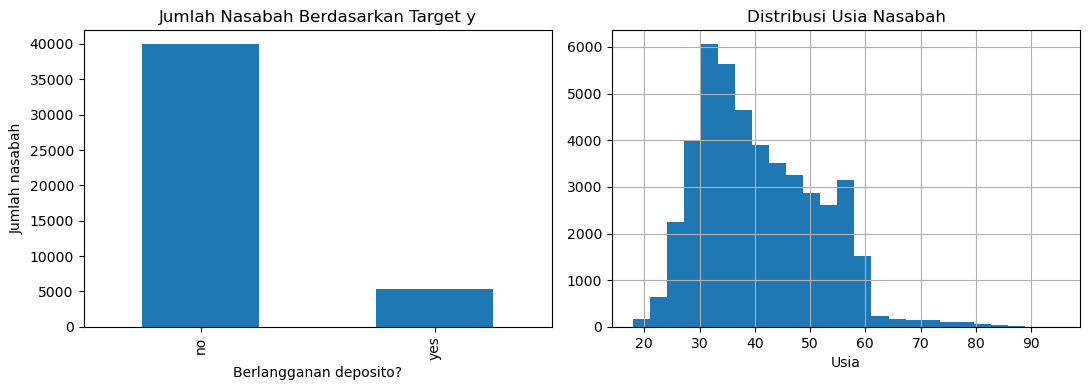

In [7]:
#202431075_Nuruliah Rifky
fig, ax = plt.subplots(1, 2, figsize=(11,4))
df['y'].value_counts().plot(kind='bar', ax=ax[0])
ax[0].set_title('Jumlah Nasabah Berdasarkan Target y')
ax[0].set_xlabel('Berlangganan deposito?')
ax[0].set_ylabel('Jumlah nasabah')
df['age'].hist(bins=25, ax=ax[1])
ax[1].set_title('Distribusi Usia Nasabah')
ax[1].set_xlabel('Usia')
plt.tight_layout()
plt.show()

## Encoding variabel target (seperti LabelEncoder pada contoh Iris)

In [8]:
#202431075_Nuruliah Rifky
df['y'] = df['y'].map({'no':0, 'yes':1})
print(df['y'].unique())
df.head()

[0 1]


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


## Encoding fitur kategorikal

In [9]:
#202431075_Nuruliah Rifky
print('Kolom kategorikal:')
print(df.select_dtypes(include='object').columns.tolist())
print('Contoh isi kolom job:', df['job'].unique())

Kolom kategorikal:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Contoh isi kolom job: ['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student']


# Modeling
## Menentukan fitur X dan target y

In [10]:
#202431075_Nuruliah Rifky
x = df.drop(['y'], axis=1)
y = df['y']
print('Fitur x:')
display(x.head())
print('Target y:')
print(y.head())

Fitur x:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown


Target y:
0    0
1    0
2    0
3    0
4    0
Name: y, dtype: int64


## Membagi data training dan testing

In [11]:
#202431075_Nuruliah Rifky
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42, stratify=y)
print('Jumlah train:', len(x_train))
print('Jumlah test:', len(x_test))

Jumlah train: 36168
Jumlah test: 9043


## Persiapan preprocessing fitur

In [12]:
#202431075_Nuruliah Rifky
kolom_numerik = x.select_dtypes(include='number').columns.tolist()
kolom_kategori = x.select_dtypes(include='object').columns.tolist()
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessing = ColumnTransformer([('num', 'passthrough', kolom_numerik), ('kat', encoder, kolom_kategori)])
print('Numerik:', kolom_numerik)
print('Kategorikal:', kolom_kategori)

Numerik: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


# Decision Tree
## Membuat dan melatih model

In [13]:
#202431075_Nuruliah Rifky
classifier = Pipeline([
    ('preprocessing', preprocessing),
    ('tree', DecisionTreeClassifier(
        criterion='gini',
        max_depth=6,
        min_samples_leaf=30,
        random_state=42
    ))
])

classifier.fit(x_train, y_train)
print('Decision Tree berhasil dilatih')

Decision Tree berhasil dilatih


# Visualisasi pohon keputusan

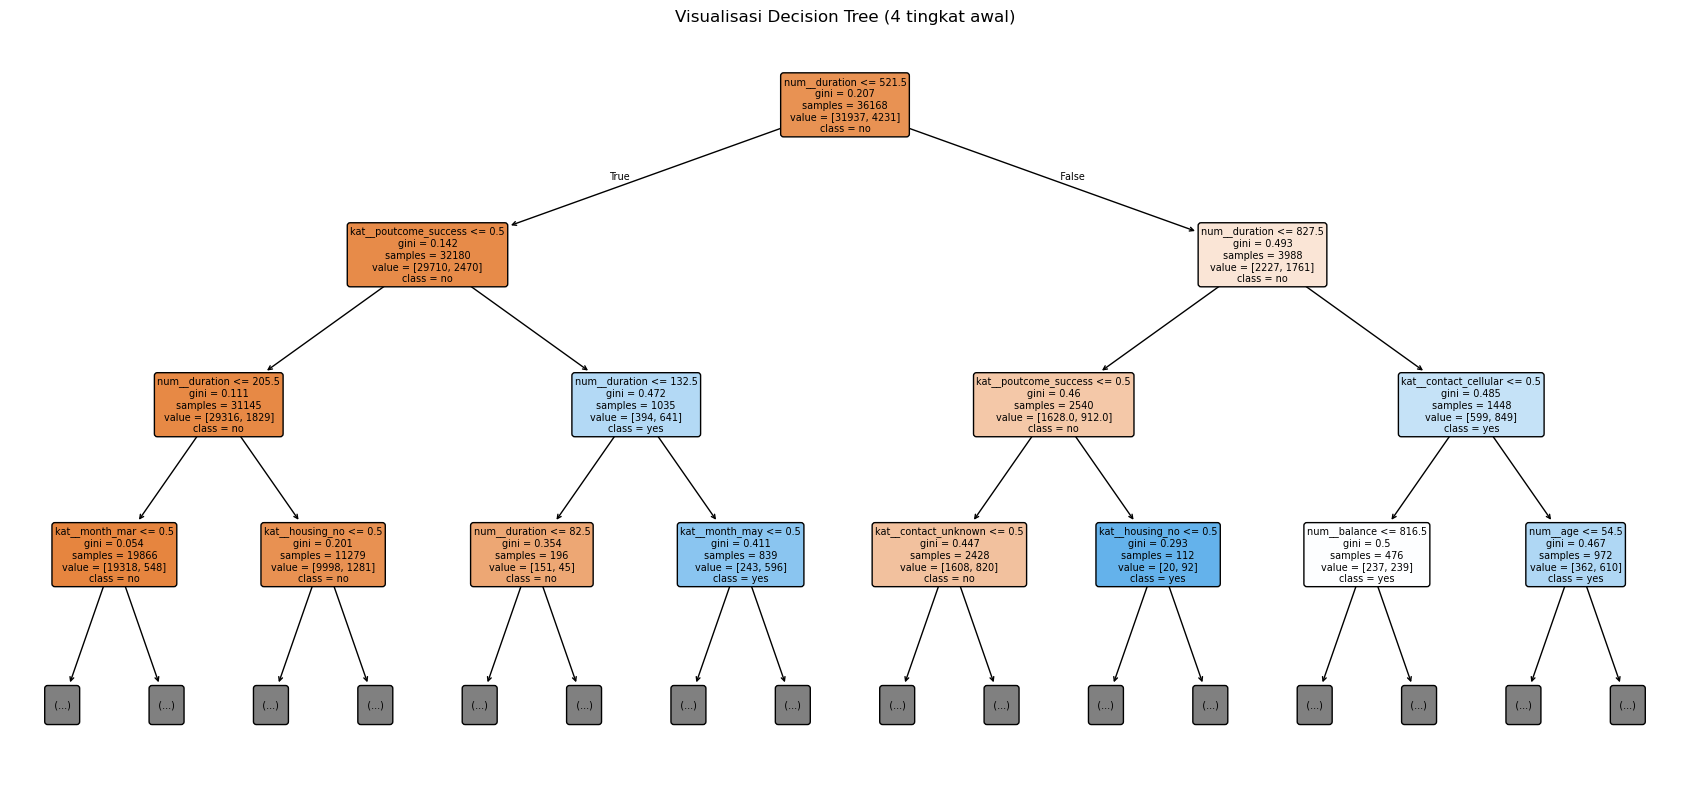

In [14]:
#202431075_Nuruliah Rifky

from sklearn import tree

nama_fitur = classifier.named_steps[
    'preprocessing'
].get_feature_names_out()

plt.figure(figsize=(17, 8))

tree.plot_tree(
    classifier.named_steps['tree'],
    feature_names=nama_fitur,
    class_names=['no', 'yes'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7
)

plt.title(
    'Visualisasi Decision Tree (4 tingkat awal)'
)
plt.tight_layout()
plt.show()

## Kedalaman pohon dan akurasi

In [15]:
#202431075_Nuruliah Rifky
depth = classifier.named_steps['tree'].get_depth()
print('Kedalaman pohon:', depth)
y_pred_tree = classifier.predict(x_test)
akurasi_tree = accuracy_score(y_test, y_pred_tree)
print('Akurasi Decision Tree:', akurasi_tree)
print('Akurasi dalam persen: {:.2f}%'.format(akurasi_tree*100))

Kedalaman pohon: 6
Akurasi Decision Tree: 0.9009178370009953
Akurasi dalam persen: 90.09%


# Naive Bayes
## Membuat dan melatih model Naive Bayes

In [16]:
#202431075_Nuruliah Rifky
naive_bayes = Pipeline([('preprocessing', preprocessing), ('nb', GaussianNB())])
naive_bayes.fit(x_train, y_train)
y_pred_nb = naive_bayes.predict(x_test)
akurasi_nb = accuracy_score(y_test, y_pred_nb)
print('Akurasi Naive Bayes:', akurasi_nb)
print('Akurasi dalam persen: {:.2f}%'.format(akurasi_nb*100))

Akurasi Naive Bayes: 0.8564635629768882
Akurasi dalam persen: 85.65%


# Evaluasi
## Hasil evaluasi kedua model

In [17]:
#202431075_Nuruliah Rifky

model = {
    'Decision Tree': classifier,
    'Naive Bayes': naive_bayes
}
hasil = []

for nama, algoritma in model.items():
    prediksi = algoritma.predict(x_test)
    peluang = algoritma.predict_proba(x_test)[:, 1]

    hasil.append({
        'Algoritma': nama,
        'Accuracy': accuracy_score(y_test, prediksi),
        'Precision': precision_score(y_test, prediksi, zero_division=0),
        'Recall': recall_score(y_test, prediksi, zero_division=0),
        'F1-score': f1_score(y_test, prediksi, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, peluang)
    })

    print('\nClassification Report:', nama)
    print(classification_report(
        y_test, prediksi, target_names=['no', 'yes']
    ))

perbandingan = pd.DataFrame(hasil).set_index('Algoritma')
display(perbandingan.round(4))


Classification Report: Decision Tree
              precision    recall  f1-score   support

          no       0.93      0.97      0.95      7985
         yes       0.61      0.41      0.49      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.69      0.72      9043
weighted avg       0.89      0.90      0.89      9043


Classification Report: Naive Bayes
              precision    recall  f1-score   support

          no       0.94      0.90      0.92      7985
         yes       0.42      0.56      0.48      1058

    accuracy                           0.86      9043
   macro avg       0.68      0.73      0.70      9043
weighted avg       0.88      0.86      0.87      9043



,Accuracy,Precision,Recall,F1-score,ROC-AUC
Algoritma,,,,,
Decision Tree,0.9009,0.6134,0.4140,0.4944,0.8654
Naive Bayes,0.8565,0.4156,0.5586,0.4766,0.8210


## Confusion Matrix

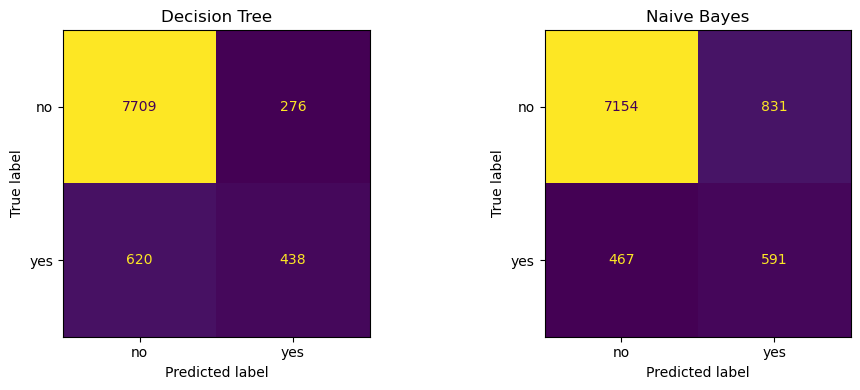

In [18]:
#202431075_Nuruliah Rifky
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, (nama, algoritma) in zip(axes, model.items()):
    cm = confusion_matrix(y_test, algoritma.predict(x_test))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no','yes']).plot(ax=ax, colorbar=False)
    ax.set_title(nama)
plt.tight_layout()
plt.show()

## Grafik perbandingan akurasi

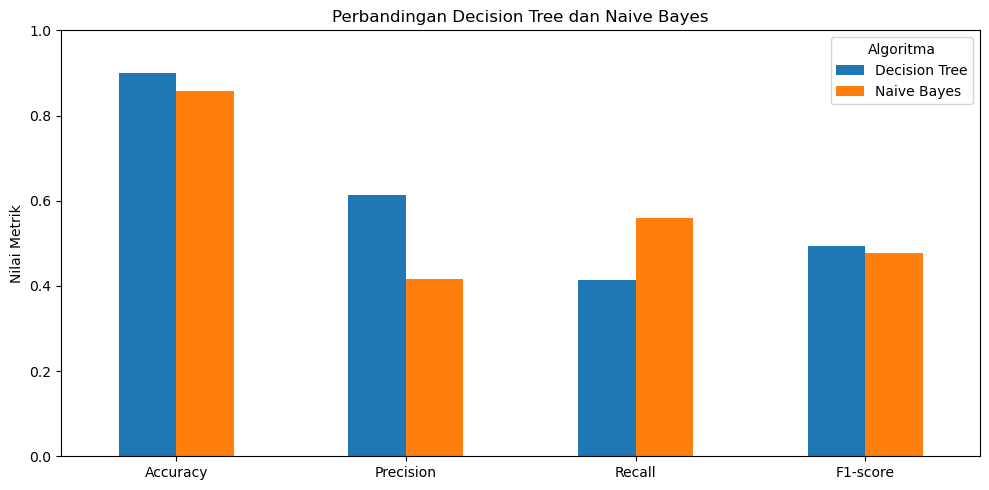

In [19]:
#202431075_Nuruliah Rifky
perbandingan[['Accuracy','Precision','Recall','F1-score']].T.plot(kind='bar', figsize=(10,5), ylim=(0,1))
plt.title('Perbandingan Decision Tree dan Naive Bayes')
plt.ylabel('Nilai Metrik')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
perbandingan.to_csv('hasil_evaluasi_sesuai_contoh.csv')